# 04 · Clasificación jerárquica en CIFAR-100

**Curso:** Fundamentos de Programación para la Inteligencia Artificial · **Autor:** William Lu Bjornestad

---

CIFAR-100 tiene 100 clases **finas** (p. ej. *maple_tree*, *oak_tree*) agrupadas en 20 **superclases** o clases gruesas (*trees*), cinco finas por cada gruesa. En este cuaderno se entrenan dos clasificadores, uno para cada nivel, y se estudia si combinar sus probabilidades mejora la predicción de la clase fina.

**Objetivos**

- Entrenar un clasificador fino (100 clases) y uno grueso (20 superclases).
- Combinar ambos mediante probabilidad condicionada usando la jerarquía de etiquetas.
- Analizar cuándo y por qué la combinación ayuda o no.

**Conceptos de pipeline de ML introducidos**

| Etapa | Qué se ve en este cuaderno |
|---|---|
| Carga de datos en bruto | Lectura del formato original del dataset para acceder a etiquetas adicionales |
| Partición compartida | Ambos modelos usan **exactamente** los mismos índices de train/val |
| Reutilización de componentes | Arquitectura, bucle y *early stopping* del cuaderno 03 |
| Composición de modelos | Combinar las salidas probabilísticas de dos modelos |
| Métricas adaptadas al problema | Top-5, exactitud por superclase y gravedad del error |

In [1]:
import copy
import math
import pickle
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
DATA_DIR = Path("../data")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cuda


## 1. Datos: etiquetas finas y gruesas

La clase `CIFAR100` de torchvision solo expone la etiqueta fina. Se usa para descargar los datos, y después se leen los ficheros originales (formato `pickle`) para obtener también la etiqueta gruesa y los nombres de las clases. Cada fila de `data` guarda los 1024 valores del canal rojo, luego el verde y luego el azul, así que `reshape(-1, 3, 32, 32)` recupera el formato $(C, H, W)$ de PyTorch.

In [2]:
datasets.CIFAR100(DATA_DIR, train=True, download=True)
datasets.CIFAR100(DATA_DIR, train=False, download=True)


def unpickle(path):
    with open(path, "rb") as f:
        return pickle.load(f, encoding="bytes")


raw_dir = DATA_DIR / "cifar-100-python"
train_raw, test_raw, meta = unpickle(raw_dir / "train"), unpickle(raw_dir / "test"), unpickle(raw_dir / "meta")
FINE_NAMES = [n.decode() for n in meta[b"fine_label_names"]]
COARSE_NAMES = [n.decode() for n in meta[b"coarse_label_names"]]


def to_tensors(raw):
    x = torch.from_numpy(raw[b"data"].reshape(-1, 3, 32, 32).astype(np.float32) / 255.0)
    return x, torch.tensor(raw[b"fine_labels"]), torch.tensor(raw[b"coarse_labels"])


x_all, yf_all, yc_all = to_tensors(train_raw)
x_test, yf_test, yc_test = to_tensors(test_raw)
print(f"Train completo: {tuple(x_all.shape)} | test: {tuple(x_test.shape)}")

Files already downloaded and verified


Files already downloaded and verified


Train completo: (50000, 3, 32, 32) | test: (10000, 3, 32, 32)


### Matriz de la jerarquía

La relación entre niveles se codifica en una matriz $M \in \{0,1\}^{20 \times 100}$ con $M_{c,f} = 1$ si la clase fina $f$ pertenece a la superclase $c$. Se construye con una única operación de indexado, sin recorrer las 50 000 etiquetas en un bucle.

In [3]:
fine_to_coarse = torch.zeros(100, dtype=torch.long)
fine_to_coarse[yf_all] = yc_all

hierarchy = torch.zeros(20, 100)
hierarchy[fine_to_coarse, torch.arange(100)] = 1.0
assert (hierarchy.sum(dim=1) == 5).all(), "cada superclase debe tener 5 clases finas"

for c in range(3):
    members = [FINE_NAMES[f] for f in torch.where(hierarchy[c] == 1)[0]]
    print(f"{COARSE_NAMES[c]:>28}: {', '.join(members)}")
print("...")

             aquatic_mammals: beaver, dolphin, otter, seal, whale
                        fish: aquarium_fish, flatfish, ray, shark, trout
                     flowers: orchid, poppy, rose, sunflower, tulip
...


## 2. Partición compartida y normalización

Se reserva un 10 % del conjunto de entrenamiento como validación. Los **dos modelos usan la misma partición**. Si cada uno tuviera la suya, imágenes que un modelo usó para entrenar formarían parte de la validación del otro, y comparar o combinar sus resultados en validación dejaría de ser válido.

La normalización por canal se calcula solo con la parte de entrenamiento, como en los cuadernos anteriores.

In [4]:
perm = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(SEED))
val_idx, train_idx = perm[:5000], perm[5000:]

mean = x_all[train_idx].mean(dim=(0, 2, 3), keepdim=True)
std = x_all[train_idx].std(dim=(0, 2, 3), keepdim=True)


def normalize(x):
    return ((x - mean) / std).to(device)


x_train, x_val, x_test_d = normalize(x_all[train_idx]), normalize(x_all[val_idx]), normalize(x_test)
labels = {
    "fine": (yf_all[train_idx].to(device), yf_all[val_idx].to(device)),
    "coarse": (yc_all[train_idx].to(device), yc_all[val_idx].to(device)),
}
print(f"Entrenamiento: {len(train_idx)} | validación: {len(val_idx)} | test: {len(x_test)}")

Entrenamiento: 45000 | validación: 5000 | test: 10000


## 3. Componentes reutilizados del cuaderno 03

Se reutilizan el cargador por lotes en GPU, el *early stopping* con restauración de pesos y el bucle `fit`. Como arquitectura se usa la CNN compacta que en el cuaderno 03 superó claramente al MLP; solo cambia el número de salidas.

> **Nota sobre la versión inicial de esta práctica:** los modelos eran `Linear(3072, 64) → Linear(64, K)` sin función de activación entre capas. Dos transformaciones lineales seguidas equivalen a una sola ($W_2(W_1x + b_1) + b_2 = W'x + b'$), así que aquel modelo era en realidad un clasificador lineal. Toda red profunda necesita no linealidades entre capas.

In [5]:
class GPUBatchLoader:
    def __init__(self, x, y, batch_size, shuffle=False):
        self.x, self.y, self.batch_size, self.shuffle = x, y, batch_size, shuffle

    def __iter__(self):
        n = len(self.x)
        idx = torch.randperm(n, device=self.x.device) if self.shuffle else torch.arange(n, device=self.x.device)
        for i in range(0, n, self.batch_size):
            batch = idx[i:i + self.batch_size]
            yield self.x[batch], self.y[batch]


class EarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience, self.min_delta = patience, min_delta
        self.best_loss, self.best_epoch, self.best_state = float("inf"), 0, None
        self.epoch = self.bad_epochs = 0

    def step(self, val_loss, model):
        self.epoch += 1
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss, self.best_epoch, self.bad_epochs = val_loss, self.epoch, 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.bad_epochs += 1
        return self.bad_epochs >= self.patience

    def restore(self, model):
        model.load_state_dict(self.best_state)


def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, lr=1e-3, max_epochs=100, patience=5, min_delta=0.005):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    stopper = EarlyStopping(patience, min_delta)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.time()
    for epoch in range(1, max_epochs + 1):
        values = run_epoch(model, train_loader, loss_fn, optimizer) + run_epoch(model, val_loader, loss_fn)
        for key, value in zip(history, values):
            history[key].append(value)
        if epoch == 1 or epoch % 5 == 0:
            print(f"Época {epoch:>3} | train loss {values[0]:.4f} | val loss {values[2]:.4f} | val acc {values[3]:.4f}")
        if stopper.step(history["val_loss"][-1], model):
            print(f"Early stopping en la época {epoch}.")
            break
    stopper.restore(model)
    history["best_epoch"] = stopper.best_epoch
    print(f"Pesos restaurados de la época {stopper.best_epoch} | tiempo {time.time() - start:.1f} s")
    return history


def make_cnn(n_classes):
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(64 * 4 * 4, 64), nn.ReLU(),
        nn.Linear(64, n_classes),
    )

## 4. Entrenamiento de los dos modelos

In [6]:
BATCH_SIZE = 256
models, histories = {}, {}
for level, n_classes in [("fine", 100), ("coarse", 20)]:
    print(f"\n=== Modelo {level} ({n_classes} clases) ===")
    y_train, y_val = labels[level]
    torch.manual_seed(SEED)
    models[level] = make_cnn(n_classes).to(device)
    histories[level] = fit(
        models[level],
        GPUBatchLoader(x_train, y_train, BATCH_SIZE, shuffle=True),
        GPUBatchLoader(x_val, y_val, 1024),
    )


=== Modelo fine (100 clases) ===


Época   1 | train loss 4.0892 | val loss 3.6696 | val acc 0.1436


Época   5 | train loss 2.7739 | val loss 2.8061 | val acc 0.3028


Época  10 | train loss 2.2940 | val loss 2.5454 | val acc 0.3568


Época  15 | train loss 2.0204 | val loss 2.4464 | val acc 0.3798


Época  20 | train loss 1.8172 | val loss 2.4163 | val acc 0.3908


... (2 outputs left out)

Época   5 | train loss 1.7188 | val loss 1.7438 | val acc 0.4516


Época  10 | train loss 1.3699 | val loss 1.5607 | val acc 0.5182


Época  15 | train loss 1.1429 | val loss 1.6084 | val acc 0.5206


Early stopping en la época 18.
Pesos restaurados de la época 13 | tiempo 133.1 s


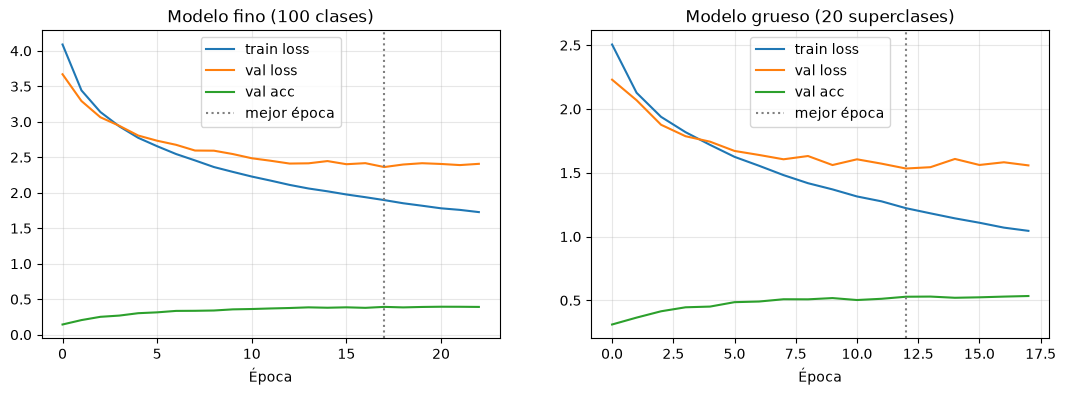

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, level in zip(axes, ["fine", "coarse"]):
    h = histories[level]
    ax.plot(h["train_loss"], label="train loss")
    ax.plot(h["val_loss"], label="val loss")
    ax.plot(h["val_acc"], label="val acc")
    ax.axvline(h["best_epoch"] - 1, color="grey", linestyle=":", label="mejor época")
    ax.set_title(f"Modelo {'fino (100 clases)' if level == 'fine' else 'grueso (20 superclases)'}")
    ax.set_xlabel("Época")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.show()

## 5. Combinación mediante probabilidad condicionada

Sea $c(f)$ la superclase de la clase fina $f$. Como cada clase fina pertenece a una única superclase, la regla de la cadena da una descomposición exacta:

$$P(f \mid x) = P(f \mid c(f), x)\; P(c(f) \mid x)$$

El modelo fino proporciona $P_{\text{fino}}(f \mid x)$ y, sumando sobre las cinco clases de cada grupo, también su propia estimación de la superclase: $P_{\text{fino}}(c \mid x) = \sum_{f \in c} P_{\text{fino}}(f \mid x)$, que en forma matricial es $P_{\text{fino}} M^\top$. El modelo grueso ofrece una segunda estimación, $P_{\text{grueso}}(c \mid x)$. Se comparan cuatro estrategias:

| Estrategia | Puntuación de la clase fina $f$ |
|---|---|
| **Base** | $P_{\text{fino}}(f \mid x)$ |
| **Producto** | $P_{\text{fino}}(f \mid x) \cdot P_{\text{grueso}}(c(f) \mid x)$ |
| **Condicional** | $\dfrac{P_{\text{fino}}(f \mid x)}{P_{\text{fino}}(c(f) \mid x)} \cdot P_{\text{grueso}}(c(f) \mid x)$ |
| **Descendente** | Elegir $\hat c = \arg\max_c P_{\text{grueso}}(c \mid x)$ y después la mejor $f \in \hat c$ según el modelo fino |

Las tres combinaciones se diferencian en cómo tratan la superclase. Usando la regla de la cadena, el producto se puede reescribir como

$$P_{\text{fino}}(f \mid x)\, P_{\text{grueso}}(c \mid x) = P_{\text{fino}}(f \mid c, x) \cdot \underbrace{P_{\text{fino}}(c \mid x)\, P_{\text{grueso}}(c \mid x)}_{\text{dos opiniones sobre la superclase}}$$

- El **producto** (la versión inicial de esta práctica) **combina** las dos estimaciones de la superclase multiplicándolas, como un pequeño *ensemble* tipo *product of experts*.
- La versión **condicional** **sustituye** la opinión del modelo fino sobre la superclase por la del modelo grueso. Es la aplicación literal de la regla de la cadena, y sería óptima si el modelo grueso diera la probabilidad real de la superclase.
- La **descendente** es la versión "dura" de la condicional.

Cuál conviene depende de una pregunta empírica: ¿el modelo grueso estima la superclase mejor que el fino, o simplemente de forma distinta?

In [8]:
def predict_proba(model, x, batch_size=1024):
    model.eval()
    with torch.no_grad():
        return torch.cat([F.softmax(model(x[i:i + batch_size]), dim=1) for i in range(0, len(x), batch_size)]).cpu()


p_fine = predict_proba(models["fine"], x_test_d)       # (N, 100)
p_coarse = predict_proba(models["coarse"], x_test_d)   # (N, 20)
p_coarse_from_fine = p_fine @ hierarchy.T              # (N, 20): superclase según el modelo fino

top_down_mask = (fine_to_coarse.unsqueeze(0) == p_coarse.argmax(dim=1, keepdim=True)).float()
scores = {
    "Base (solo fino)": p_fine,
    "Producto": p_fine * p_coarse[:, fine_to_coarse],
    "Condicional": p_fine / p_coarse_from_fine[:, fine_to_coarse] * p_coarse[:, fine_to_coarse],
    "Descendente": p_fine * top_down_mask,
}

### Métricas

Además de la exactitud *top-1*, se usan métricas que tienen en cuenta la jerarquía:

- **Top-5**: la clase correcta está entre las cinco más probables. Es la métrica estándar con muchas clases.
- **Exactitud de superclase**: aunque la clase fina sea errónea, ¿pertenece al grupo correcto?
- **Errores graves**: de los fallos, qué fracción cae además en otra superclase. Confundir un roble con un arce es menos grave que confundirlo con un camión.

In [9]:
def hierarchical_metrics(score):
    pred = score.argmax(dim=1)
    top5 = score.topk(5, dim=1).indices
    wrong = pred != yf_test
    wrong_coarse = fine_to_coarse[pred] != yc_test
    return {
        "top-1": (~wrong).float().mean().item(),
        "top-5": (top5 == yf_test.unsqueeze(1)).any(dim=1).float().mean().item(),
        "acc. superclase": (~wrong_coarse).float().mean().item(),
        "errores graves (% de fallos)": (wrong & wrong_coarse).sum().item() / wrong.sum().item(),
    }


results_df = pd.DataFrame({name: hierarchical_metrics(s) for name, s in scores.items()}).T
(results_df * 100).round(2)

,top-1,top-5,acc. superclase,errores graves (% de fallos)
Base (solo fino),40.38,71.21,54.06,77.05
Producto,42.15,71.76,58.14,72.36
Condicional,39.33,69.83,54.37,75.21
Descendente,37.98,53.56,53.56,74.88


### ¿Aporta algo el modelo grueso?

La tabla responde a la pregunta anterior de forma inesperada: el producto mejora al modelo base, pero la versión condicional, en principio la más "correcta", lo empeora. Para entenderlo se comparan directamente las dos estimaciones de la superclase: la del modelo grueso y la que se obtiene **marginalizando** el modelo fino.

In [10]:
acc_coarse_model = (p_coarse.argmax(dim=1) == yc_test).float().mean().item()
acc_coarse_from_fine = (p_coarse_from_fine.argmax(dim=1) == yc_test).float().mean().item()
agreement = (p_coarse.argmax(dim=1) == p_coarse_from_fine.argmax(dim=1)).float().mean().item()

print(f"Exactitud de superclase del modelo grueso:          {acc_coarse_model:.4f}")
print(f"Exactitud de superclase marginalizando el fino:     {acc_coarse_from_fine:.4f}")
print(f"Acuerdo entre ambas estimaciones de la superclase:  {agreement:.4f}")

base_ok = scores["Base (solo fino)"].argmax(dim=1) == yf_test
cond_ok = scores["Condicional"].argmax(dim=1) == yf_test
print(f"\nCondicional frente a base: corrige {(~base_ok & cond_ok).sum().item()} imágenes "
      f"y estropea {(base_ok & ~cond_ok).sum().item()} de {len(yf_test)}")

Exactitud de superclase del modelo grueso:          0.5356
Exactitud de superclase marginalizando el fino:     0.5502
Acuerdo entre ambas estimaciones de la superclase:  0.5810

Condicional frente a base: corrige 686 imágenes y estropea 791 de 10000


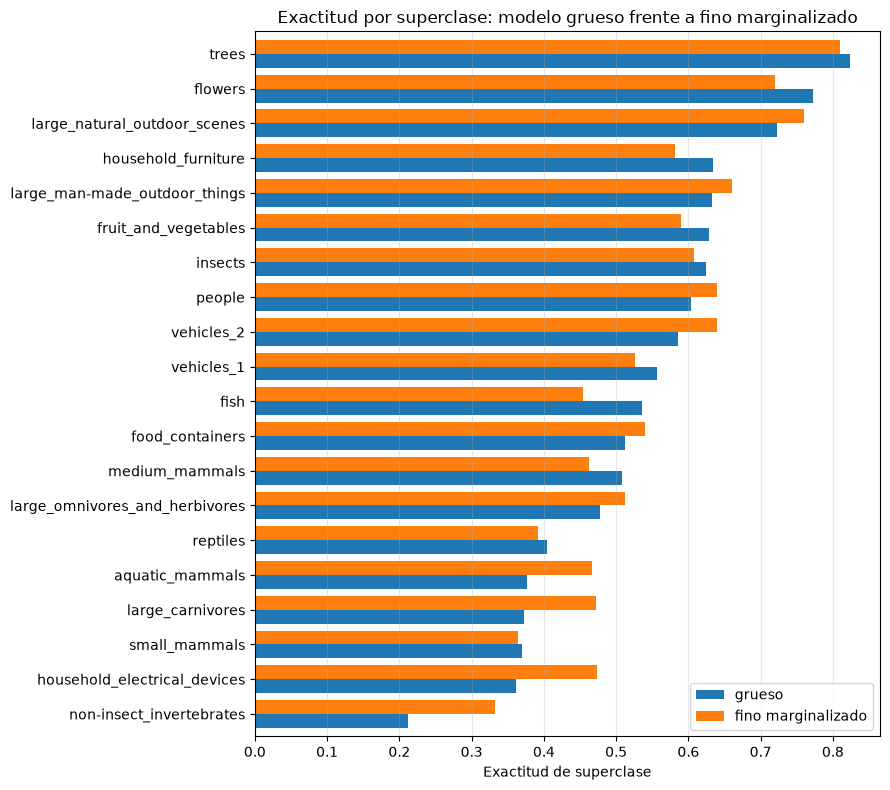

In [11]:
per_class = pd.DataFrame({
    "grueso": [(p_coarse.argmax(1)[yc_test == c] == c).float().mean().item() for c in range(20)],
    "fino marginalizado": [(p_coarse_from_fine.argmax(1)[yc_test == c] == c).float().mean().item() for c in range(20)],
}, index=COARSE_NAMES).sort_values("grueso")

per_class.plot.barh(figsize=(9, 8), width=0.8)
plt.xlabel("Exactitud de superclase")
plt.title("Exactitud por superclase: modelo grueso frente a fino marginalizado")
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación

- **El modelo grueso es peor prediciendo superclases que el fino marginalizado.** Parece contradictorio, porque 20 clases deberían ser más fáciles que 100. Pero muchas superclases de CIFAR-100 son **visualmente heterogéneas**: *non-insect_invertebrates* agrupa cangrejos, langostas, caracoles, arañas y gusanos, y *household_electrical_devices* agrupa relojes, teclados, lámparas, teléfonos y televisores. Para el modelo grueso son una sola clase sin un aspecto común. El modelo fino aprende cada objeto por separado, y sumar sus probabilidades da mejor resultado. **Etiquetas más finas proporcionan una supervisión más informativa**, aunque la tarea final sea gruesa.
- **Las dos estimaciones son complementarias.** El modelo grueso gana en superclases de aspecto homogéneo (árboles, flores, insectos, peces) y el fino marginalizado en las heterogéneas. Coinciden en poco más de la mitad de las imágenes, así que sus errores están lejos de ser idénticos.
- **Eso explica la tabla.** La versión condicional *sustituye* la mejor de las dos estimaciones por la peor y empeora. El producto las *combina*, y combinar dos opiniones parcialmente independientes mejora a cualquiera de las dos por separado: es el principio de los *ensembles*. La estrategia descendente es la peor porque además se compromete con una sola superclase, y sus errores de primer nivel ya no se pueden corregir.

## 6. Ajuste del peso de la combinación en validación

El producto da el mismo peso a los dos modelos. Una generalización natural es

$$\text{score}(f) = P_{\text{fino}}(f \mid x) \cdot P_{\text{grueso}}(c(f) \mid x)^{\,w},$$

que en escala logarítmica es una suma ponderada $\log P_{\text{fino}} + w \log P_{\text{grueso}}$. Con $w = 0$ se recupera el modelo base, y con $w = 1$ el producto. El peso $w$ es un **hiperparámetro**, así que se elige en **validación** y solo después se evalúa en test.

Aquí se ve por qué era importante la partición compartida. Si el modelo grueso hubiera entrenado con imágenes de la validación del modelo fino, sus probabilidades serían demasiado confiadas en ese conjunto y el peso elegido estaría sesgado.

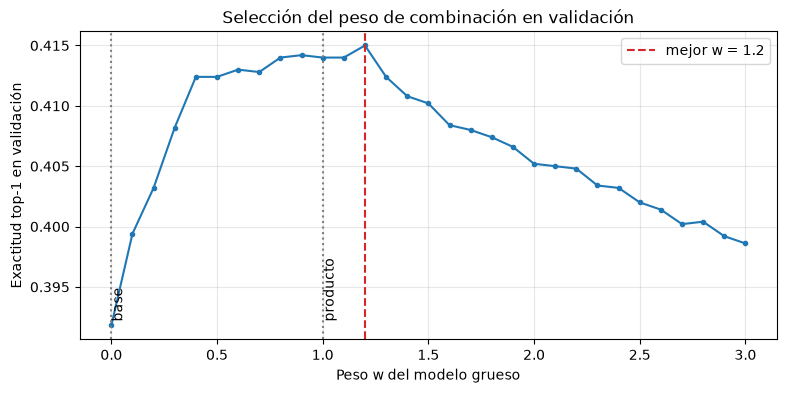

,top-1,top-5,acc. superclase,errores graves (% de fallos)
Base (solo fino),40.38,71.21,54.06,77.05
Producto,42.15,71.76,58.14,72.36
Condicional,39.33,69.83,54.37,75.21
Descendente,37.98,53.56,53.56,74.88
Producto ponderado (w = 1.2),42.03,71.42,58.10,72.28


In [12]:
y_val_fine = labels["fine"][1].cpu()
p_fine_val = predict_proba(models["fine"], x_val)
p_coarse_val = predict_proba(models["coarse"], x_val)

weights = np.round(np.linspace(0, 3, 31), 2)
val_acc = [((p_fine_val * p_coarse_val[:, fine_to_coarse] ** w).argmax(dim=1) == y_val_fine).float().mean().item()
           for w in weights]
best_w = float(weights[int(np.argmax(val_acc))])

plt.figure(figsize=(9, 4))
plt.plot(weights, val_acc, marker=".")
for w, name in [(0, "base"), (1, "producto")]:
    plt.axvline(w, color="grey", linestyle=":")
    plt.text(w, min(val_acc), f" {name}", rotation=90, va="bottom")
plt.axvline(best_w, color="tab:red", linestyle="--", label=f"mejor w = {best_w}")
plt.xlabel("Peso w del modelo grueso")
plt.ylabel("Exactitud top-1 en validación")
plt.title("Selección del peso de combinación en validación")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

scores[f"Producto ponderado (w = {best_w})"] = p_fine * p_coarse[:, fine_to_coarse] ** best_w
results_df = pd.DataFrame({name: hierarchical_metrics(s) for name, s in scores.items()}).T
(results_df * 100).round(2)

## 7. Conclusiones

- **Una red sin no linealidades es un modelo lineal.** Corregir la arquitectura (y pasar a una CNN) duplica con creces la exactitud de la versión inicial de esta práctica, que rondaba el 18 %.
- **Lo teóricamente exacto no siempre es lo mejor en la práctica.** La descomposición condicional sería óptima si el modelo grueso diera la probabilidad real de la superclase. Como es un estimador imperfecto, y peor que el fino marginalizado, sustituir una estimación por otra empeora el resultado.
- **Combinar opiniones complementarias sí ayuda.** El producto funciona como un *ensemble* de dos estimaciones de la superclase que fallan en sitios distintos: uno domina en superclases homogéneas y el otro en las heterogéneas. Ajustar su peso en validación convierte la combinación en un hiperparámetro más del pipeline. La curva de validación muestra una meseta amplia (cualquier $w$ entre 0.4 y 1.2 da resultados casi iguales), con el máximo en $w = 1.2$. En test rinde igual que el producto simple: la diferencia de una décima equivale a una decena de imágenes y está dentro del ruido estadístico. Es decir, la validación confirma que el producto con pesos iguales ya estaba cerca del óptimo, y evita la tentación de elegir la variante que mejor sale en test.
- **La granularidad de las etiquetas importa.** Entrenar con etiquetas finas y agregar después da mejores superclases que entrenar directamente con las gruesas, porque las superclases mezclan objetos que no se parecen.
- **La estrategia descendente es arriesgada.** Si la superclase elegida es errónea, la clase fina ya no puede acertar. Las estrategias "blandas" conservan la incertidumbre y son más robustas.
- **La jerarquía sirve para medir.** La exactitud de superclase y la proporción de errores graves (en torno a tres de cada cuatro fallos cruzan de superclase) describen mejor la calidad de un clasificador con 100 clases que el *top-1* aislado.
- **Formas más eficaces de usar la jerarquía**: una sola red con dos cabezas (fina y gruesa) que compartan el extractor de características (*multi-task learning*), una pérdida que penalice más los errores entre superclases, o *label smoothing* jerárquico que reparta la probabilidad entre clases hermanas.

**Siguiente paso:** hasta aquí todos los modelos han sido supervisados. El cuaderno 05 pasa al **aprendizaje no supervisado** con autoencoders, donde el objetivo es aprender una representación comprimida de los datos sin usar etiquetas.